# D01 · PCA: компактные признаки для модели

**Связь со слайдом 1.** Каждая строка исходной таблицы остаётся одним объектом, но вместо 64 пикселей получает $k$ новых координат. Затем отдельно проверяем, насколько такое представление полезно классификатору.

**За 5–10 минут:** реальные изображения цифр → таблица → StandardScaler → PCA через SVD → компактная таблица → логистическая регрессия. Ранг выбираем только по validation, а отложенный test открываем в конце.

Набор `load_digits` встроен в scikit-learn: 1 797 изображений 8×8, значения пикселей 0…16. Загрузка данных и выполнение после установки библиотек работают без сети. Это небольшой учебный набор; результаты не являются оценкой промышленного OCR.

**Запуск.** Выберите Python-ядро с зависимостями и выполните **Restart Kernel → Run All**. Установка в терминале, если нужна:

```bash
python -m pip install numpy scipy pandas matplotlib scikit-learn threadpoolctl ipykernel
```

Все ячейки самодостаточны; другой ноутбук предварительно запускать не требуется. Рабочий каталог — папка этого ноутбука; результаты сохраняются только в `outputs/d01/`.


In [1]:
from pathlib import Path

# Изменяйте эти параметры, затем запускайте ноутбук целиком.
SEED = 42
TEST_SIZE = 0.25              # То же разбиение используется в D02.
VALIDATION_SIZE = 0.20       # Доля внутри train, test сюда не входит.
DEMO_RANK = 16               # Для таблицы, ручной SVD и восстановления.
RANKS = [2, 4, 8, 16, 24, 32, 48]
LOGREG_C = 1.0               # Фиксирован до просмотра test.
OUTPUT_DIR = Path("outputs/d01")


In [2]:
from pathlib import Path
from time import perf_counter
from datetime import datetime, timezone
import platform
import os
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import scipy
from IPython.display import display, Markdown
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from threadpoolctl import threadpool_limits, threadpool_info

# Ограничиваем BLAS одним потоком: маленькая задача и воспроизводимый режим CPU.
thread_limit = threadpool_limits(limits=1)
np.random.seed(SEED)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
started_at = perf_counter()
environment = {
    "seed": SEED, "device": "CPU", "python": platform.python_version(),
    "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
    "scikit_learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
    "platform": platform.platform(), "machine": platform.machine(),
    "logical_cpus": os.cpu_count(), "blas_threads": 1,
    "run_utc": datetime.now(timezone.utc).isoformat(),
    "blas": [{k: p.get(k) for k in ("internal_api", "version", "num_threads")}
             for p in threadpool_info()],
}
display(pd.Series(environment).to_frame("Среда запуска"))

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay


Matplotlib is building the font cache; this may take a moment.


,Среда запуска
seed,42
device,CPU
python,3.12.14
numpy,2.5.3
pandas,3.0.6
scipy,1.18.1
scikit_learn,1.9.1
matplotlib,3.11.2
platform,macOS-26.6.2-arm64-arm-64bit
machine,arm64


## 1. Одна строка — одна цифра

Назначим идентификаторы **до разбиения**. `digit-0000` всегда означает нулевое изображение встроенного набора. D02 использует те же идентификаторы и тот же train/test. Стратификация сохраняет приблизительные доли цифр в обеих частях.

И метки, и test нужны для проверки задачи. Они не участвуют в обучении PCA. `StandardScaler` и PCA ниже получают только обучающие строки.


Всего: (1797, 64); train: (1347, 64); test: (450, 64)
Отпечаток разбиения D01/D02: 6dc3375408b6b269


,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7
object_id,,,,,,,,
digit-0730,0.0,2.0,12.0,16.0,12.0,0.0,0.0,0.0
digit-1590,0.0,0.0,0.0,13.0,14.0,0.0,0.0,0.0
digit-0313,0.0,2.0,11.0,16.0,12.0,1.0,0.0,0.0
digit-0987,0.0,0.0,11.0,10.0,0.0,0.0,0.0,0.0
digit-0094,0.0,0.0,3.0,12.0,16.0,10.0,0.0,0.0


Показаны 8 из 64 пикселей; таблица целиком: (1347, 64)


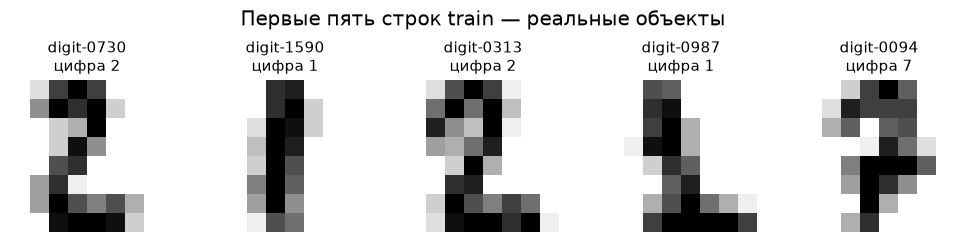

In [3]:
digits = load_digits()
X = digits.data.astype(np.float64)
y = digits.target.copy()
object_ids = np.array([f"digit-{i:04d}" for i in range(len(X))])
all_idx = np.arange(len(X))
train_idx, test_idx = train_test_split(
    all_idx, test_size=TEST_SIZE, random_state=SEED, stratify=y
)
X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
train_ids, test_ids = object_ids[train_idx], object_ids[test_idx]

assert len(set(object_ids)) == len(X)
assert np.intersect1d(train_idx, test_idx).size == 0
assert np.array_equal(np.sort(np.r_[train_idx, test_idx]), all_idx)
assert len(train_idx) + len(test_idx) == len(X) == 1797
assert X.shape[1] == 64
split_fingerprint = hashlib.sha256(
    np.r_[train_idx, [-1], test_idx].astype("<i8").tobytes()
).hexdigest()[:16]
print(f"Всего: {X.shape}; train: {X_train.shape}; test: {X_test.shape}")
print("Отпечаток разбиения D01/D02:", split_fingerprint)
feature_names = [f"pixel_{r}_{c}" for r in range(8) for c in range(8)]
original_table = pd.DataFrame(X_train, index=train_ids, columns=feature_names)
original_table.index.name = "object_id"

display(original_table.iloc[:5, :8].round(1))
print("Показаны 8 из 64 пикселей; таблица целиком:", original_table.shape)
fig, axes = plt.subplots(1, 5, figsize=(9, 2.1), layout="constrained")
for ax, idx in zip(axes, train_idx[:5]):
    ax.imshow(digits.images[idx], cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(f"{object_ids[idx]}\nцифра {y[idx]}", fontsize=10)
    ax.set_axis_off()
fig.suptitle("Первые пять строк train — реальные объекты", fontsize=13)
fig.savefig(OUTPUT_DIR / "01_objects.png", dpi=150)
plt.show()


## 2. Из 64 признаков в $k$ координат

Пусть $X_s$ — таблица после стандартизации по train. Центрируем её: $A=X_s-\mu$. Для SVD $A=U\Sigma V^\top$ PCA оставляет первые $k$ направлений:

$$Z=A V_k=U_k\Sigma_k,\qquad \widehat X_s=ZV_k^\top+\mu.$$

Меняется число **столбцов**, а число **строк** и их порядок сохраняются. PCA в scikit-learn центрирует, но не стандартизирует признаки автоматически. Масштабирование здесь — явный учебный выбор: оно уравнивает дисперсии пикселей, включая редко меняющиеся. Для пикселей одного масштаба полезно отдельно сравнить PCA без масштабирования.

Этот блок показывает преобразование на всём train. Для выбора ранга дальше будут **заново** обучены scaler и PCA только на внутренней обучающей части; объекты validation не попадут в их `fit`.


In [4]:
assert 1 <= DEMO_RANK < X.shape[1]
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)
pca_demo = PCA(n_components=DEMO_RANK, svd_solver="full").fit(X_train_scaled)
Z_train = pca_demo.transform(X_train_scaled)
Z_test = pca_demo.transform(X_test_scaled)
compact_table = pd.DataFrame(
    Z_train, index=train_ids, columns=[f"PC{i + 1}" for i in range(DEMO_RANK)]
)
compact_table.index.name = "object_id"
scaled_table = pd.DataFrame(X_train_scaled, index=train_ids, columns=feature_names)
scaled_table.index.name = "object_id"
assert original_table.index.equals(compact_table.index)
assert Z_train.shape == (len(train_idx), DEMO_RANK)
assert Z_test.shape == (len(test_idx), DEMO_RANK)
np.testing.assert_allclose(scaler.mean_, X_train.mean(axis=0), atol=1e-12)
np.testing.assert_allclose(pca_demo.mean_, X_train_scaled.mean(axis=0), atol=1e-12)
np.testing.assert_allclose(Z_train.mean(axis=0), 0, atol=1e-12)

for name, frame in [("Исходные 64 пикселя (первые 8)", original_table.iloc[:5, :8]),
                    ("После StandardScaler (те же 8)", scaled_table.iloc[:5, :8]),
                    (f"Компактные {DEMO_RANK} признаков (первые 6)", compact_table.iloc[:5, :6])]:
    display(Markdown(f"**{name}**"))
    display(frame.round(3))
print(f"{X_train.shape} → {Z_train.shape}: ни одна строка не удалена")
print(f"Доля сохранённой дисперсии train: {pca_demo.explained_variance_ratio_.sum():.1%}")
print(f"Память таблицы float64: {X_train.nbytes / 1024:.1f} → {Z_train.nbytes / 1024:.1f} КиБ")
print("Это память признаков; сюда не включены scaler, матрица PCA и модель.")


**Исходные 64 пикселя (первые 8)**

,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7
object_id,,,,,,,,
digit-0730,0.0,2.0,12.0,16.0,12.0,0.0,0.0,0.0
digit-1590,0.0,0.0,0.0,13.0,14.0,0.0,0.0,0.0
digit-0313,0.0,2.0,11.0,16.0,12.0,1.0,0.0,0.0
digit-0987,0.0,0.0,11.0,10.0,0.0,0.0,0.0,0.0
digit-0094,0.0,0.0,3.0,12.0,16.0,10.0,0.0,0.0


**После StandardScaler (те же 8)**

,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7
object_id,,,,,,,,
digit-0730,0.0,1.844,1.455,0.990,0.034,-1.032,-0.402,-0.117
digit-1590,0.0,-0.332,-1.101,0.281,0.498,-1.032,-0.402,-0.117
digit-0313,0.0,1.844,1.242,0.990,0.034,-0.855,-0.402,-0.117
digit-0987,0.0,-0.332,1.242,-0.427,-2.746,-1.032,-0.402,-0.117
digit-0094,0.0,-0.332,-0.462,0.045,0.961,0.738,-0.402,-0.117


**Компактные 16 признаков (первые 6)**

,PC1,PC2,PC3,PC4,PC5,PC6
object_id,,,,,,
digit-0730,4.049,-1.763,1.133,-1.399,-1.848,2.890
digit-1590,0.022,1.292,4.633,0.861,-1.003,-0.301
digit-0313,5.949,-1.826,1.389,-1.828,-0.049,1.806
digit-0987,2.408,-2.466,4.054,0.345,4.528,0.828
digit-0094,-0.076,2.790,0.538,-0.327,-0.535,-2.310


(1347, 64) → (1347, 16): ни одна строка не удалена
Доля сохранённой дисперсии train: 72.7%
Память таблицы float64: 673.5 → 168.4 КиБ
Это память признаков; сюда не включены scaler, матрица PCA и модель.


## 3. Проверяем PCA ручной SVD

Знак сингулярного вектора не фиксирован: $v$ и $-v$ задают одну ось. При совпадающих сингулярных значениях возможен также поворот базиса внутри соответствующего подпространства. Поэтому проверяем **подпространство и координаты после согласования базиса**, а не требуем побитового совпадения векторов.

Формула для объяснённой дисперсии: $\lambda_j=\sigma_j^2/(n-1)$. Ошибка восстановления в стандартизованных координатах равна энергии отброшенных сингулярных значений.


In [5]:
A = X_train_scaled - X_train_scaled.mean(axis=0)
U, singular_values, Vt = np.linalg.svd(A, full_matrices=False)
V_manual = Vt[:DEMO_RANK].T
V_sklearn = pca_demo.components_.T
# Если базисы отличаются только знаками, эта матрица диагональна с ±1.
# В общем случае она согласует ортонормированные базисы одного подпространства.
alignment = V_manual.T @ V_sklearn
Z_manual = A @ V_manual
projector_error = np.linalg.norm(
    V_manual @ V_manual.T - V_sklearn @ V_sklearn.T, ord="fro"
)
np.testing.assert_allclose(V_manual @ alignment, V_sklearn, atol=1e-10)
np.testing.assert_allclose(Z_manual @ alignment, Z_train, atol=1e-9)
np.testing.assert_allclose(
    pca_demo.explained_variance_, singular_values[:DEMO_RANK] ** 2 / (len(A) - 1),
    rtol=1e-10, atol=1e-12
)
reconstructed_scaled = pca_demo.inverse_transform(Z_train)
residual_energy = np.linalg.norm(A - Z_manual @ V_manual.T, ord="fro") ** 2
np.testing.assert_allclose(
    residual_energy, np.sum(singular_values[DEMO_RANK:] ** 2), rtol=1e-10
)
print(f"Ошибка между проекторами подпространств: {projector_error:.3e}")
print(f"Максимальное расхождение согласованных координат: {np.max(np.abs(Z_manual @ alignment - Z_train)):.3e}")
print("Диагональ согласования (знаки первых осей):", np.round(np.diag(alignment)[:8], 3))
print(f"Отброшенная доля энергии: {residual_energy / np.sum(A ** 2):.1%}")


Ошибка между проекторами подпространств: 0.000e+00
Максимальное расхождение согласованных координат: 5.684e-14
Диагональ согласования (знаки первых осей): [-1. -1. -1. -1.  1.  1.  1. -1.]
Отброшенная доля энергии: 27.3%


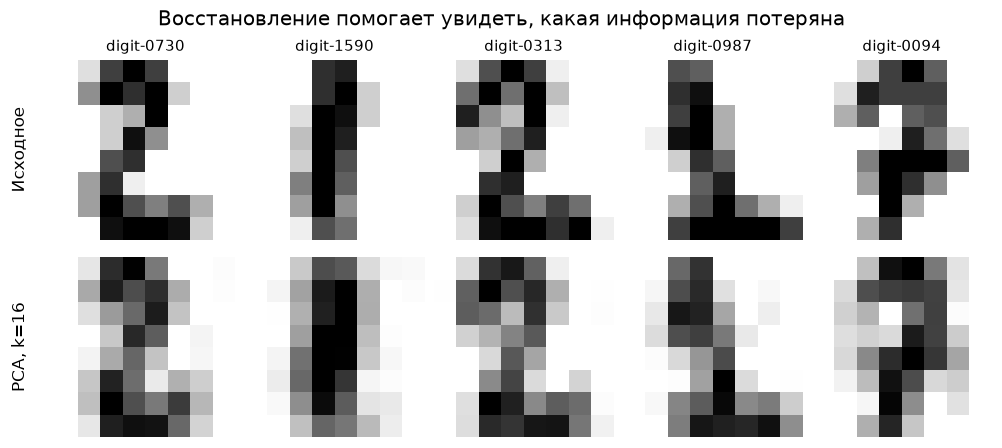

Общий цветовой диапазон 0…16; значения восстановления вне диапазона ограничены только при отображении.


In [6]:
variance_ratio = singular_values ** 2 / np.sum(singular_values ** 2)
reconstructed = scaler.inverse_transform(reconstructed_scaled)
fig, axes = plt.subplots(2, 5, figsize=(9, 4), layout="constrained")
for col, idx in enumerate(train_idx[:5]):
    axes[0, col].imshow(X_train[col].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    axes[0, col].set_title(object_ids[idx], fontsize=10)
    axes[1, col].imshow(reconstructed[col].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    for row in range(2):
        axes[row, col].set_axis_off()
axes[0, 0].text(-0.2, 0.5, "Исходное", transform=axes[0, 0].transAxes,
                rotation=90, va="center", ha="center")
axes[1, 0].text(-0.2, 0.5, f"PCA, k={DEMO_RANK}", transform=axes[1, 0].transAxes,
                rotation=90, va="center", ha="center")
fig.suptitle("Восстановление помогает увидеть, какая информация потеряна", fontsize=13)
fig.savefig(OUTPUT_DIR / "02_reconstruction.png", dpi=150)
plt.show()
print("Общий цветовой диапазон 0…16; значения восстановления вне диапазона ограничены только при отображении.")


## 4. Ранг выбираем без доступа к test

Выделяем validation **внутри train**. Scaler и PCA обучаем на `fit_idx`. Для каждого заранее заданного $k$ используем первые $k$ координат одной полной SVD и обучаем одну и ту же логистическую регрессию. Для `svd_solver='full'` это соответствует отдельному PCA ранга $k$.

Правило заранее фиксировано: максимальная validation accuracy, при равенстве — меньший ранг. Это простая демонстрация с одним validation split, а не полноценный подбор гиперпараметров с кросс-валидацией. Базовый классификатор использует все 64 стандартизованных пикселя.


,variance_fit,validation_accuracy,classifier_fit_ms,feature_fraction
rank,,,,
2,0.2188,0.5815,15.0648,0.0312
4,0.3720,0.7815,11.7943,0.0625
8,0.5401,0.8444,13.2408,0.1250
16,0.7385,0.9444,12.0250,0.2500
24,0.8521,0.9593,11.9099,0.3750
32,0.9163,0.9778,9.9054,0.5000
48,0.9819,0.9704,10.3133,0.7500


Без PCA: validation accuracy = 0.9667
Выбран k=32; test до этого момента не оценивался.


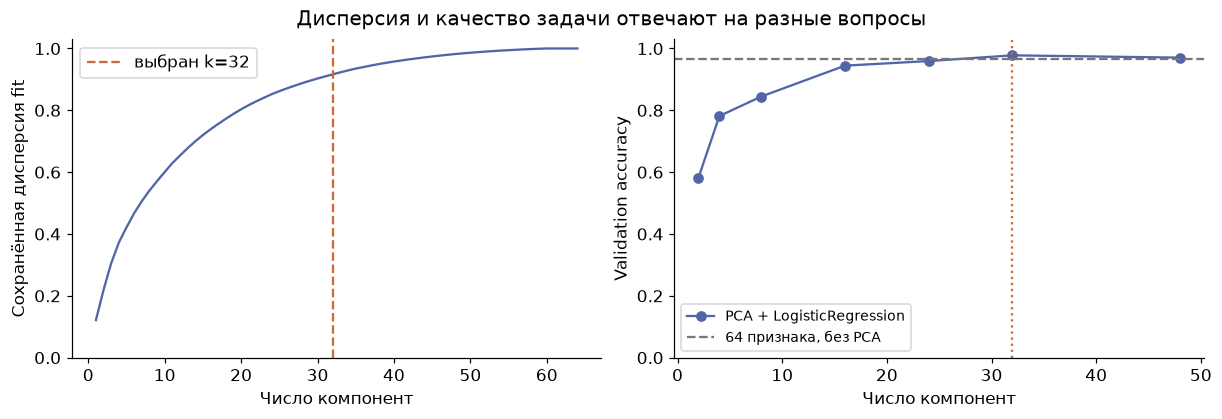

In [7]:
fit_idx, val_idx = train_test_split(
    train_idx, test_size=VALIDATION_SIZE, random_state=SEED, stratify=y[train_idx]
)
assert np.intersect1d(fit_idx, val_idx).size == 0
assert np.intersect1d(np.r_[fit_idx, val_idx], test_idx).size == 0
assert np.array_equal(np.sort(np.r_[fit_idx, val_idx]), np.sort(train_idx))
assert all(1 <= k < X.shape[1] for k in RANKS)

selection_scaler = StandardScaler().fit(X[fit_idx])
X_fit_s = selection_scaler.transform(X[fit_idx])
X_val_s = selection_scaler.transform(X[val_idx])
selection_pca = PCA(svd_solver="full").fit(X_fit_s)
Z_fit_all = selection_pca.transform(X_fit_s)
Z_val_all = selection_pca.transform(X_val_s)
np.testing.assert_allclose(selection_scaler.mean_, X[fit_idx].mean(axis=0), atol=1e-12)

def new_classifier():
    return LogisticRegression(C=LOGREG_C, solver="lbfgs", max_iter=3000,
                              tol=1e-6, random_state=SEED)

rows = []
for rank in sorted(set(RANKS)):
    model = new_classifier()
    tick = perf_counter()
    model.fit(Z_fit_all[:, :rank], y[fit_idx])
    elapsed = perf_counter() - tick
    assert model.n_iter_.max() < model.max_iter, "Увеличьте max_iter: оптимизация не сошлась"
    pred = model.predict(Z_val_all[:, :rank])
    rows.append({"rank": rank,
                 "variance_fit": selection_pca.explained_variance_ratio_[:rank].sum(),
                 "validation_accuracy": accuracy_score(y[val_idx], pred),
                 "classifier_fit_ms": elapsed * 1000,
                 "feature_fraction": rank / X.shape[1]})
rank_results = pd.DataFrame(rows).set_index("rank")
baseline_val = new_classifier().fit(X_fit_s, y[fit_idx])
assert baseline_val.n_iter_.max() < baseline_val.max_iter
baseline_val_accuracy = accuracy_score(y[val_idx], baseline_val.predict(X_val_s))
selected_rank = int(rank_results["validation_accuracy"].idxmax())
display(rank_results.round(4))
print(f"Без PCA: validation accuracy = {baseline_val_accuracy:.4f}")
print(f"Выбран k={selected_rank}; test до этого момента не оценивался.")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), layout="constrained")
axes[0].plot(np.arange(1, 65), np.cumsum(selection_pca.explained_variance_ratio_), color="#5165A8")
axes[0].axvline(selected_rank, color="#CC6B36", ls="--", label=f"выбран k={selected_rank}")
axes[0].set(xlabel="Число компонент", ylabel="Сохранённая дисперсия fit", ylim=(0, 1.03))
axes[0].legend()
axes[1].plot(rank_results.index, rank_results.validation_accuracy, "o-", color="#5165A8", label="PCA + LogisticRegression")
axes[1].axhline(baseline_val_accuracy, ls="--", color="#777777", label="64 признака, без PCA")
axes[1].axvline(selected_rank, ls=":", color="#CC6B36")
axes[1].set(xlabel="Число компонент", ylabel="Validation accuracy", ylim=(0, 1.03))
axes[1].legend(fontsize=9)
fig.suptitle("Дисперсия и качество задачи отвечают на разные вопросы", fontsize=13)
fig.savefig(OUTPUT_DIR / "03_rank_tradeoff.png", dpi=150)
plt.show()


## 5. Одна финальная оценка на test

Выбранный ранг уже зафиксирован. Теперь переобучаем обе цепочки на **всём train** и сравниваем test accuracy и macro-F1. Все преобразования внутри `Pipeline` обучаются вместе с моделью только на переданном train.

Измеряем wall-clock время одной попытки в текущем окружении CPU. `fit_ms` включает scaler, PCA (если есть) и классификатор; `predict_ms` включает все преобразования test. На таком маленьком наборе задержки нестабильны: это наблюдение, не бенчмарк и не доказательство ускорения.


,features,test_accuracy,test_macro_f1,fit_ms,predict_ms
model,,,,,
64 пикселя,64,0.9778,0.9776,13.5190,0.2175
PCA k=32,32,0.9467,0.9466,15.7957,0.2760


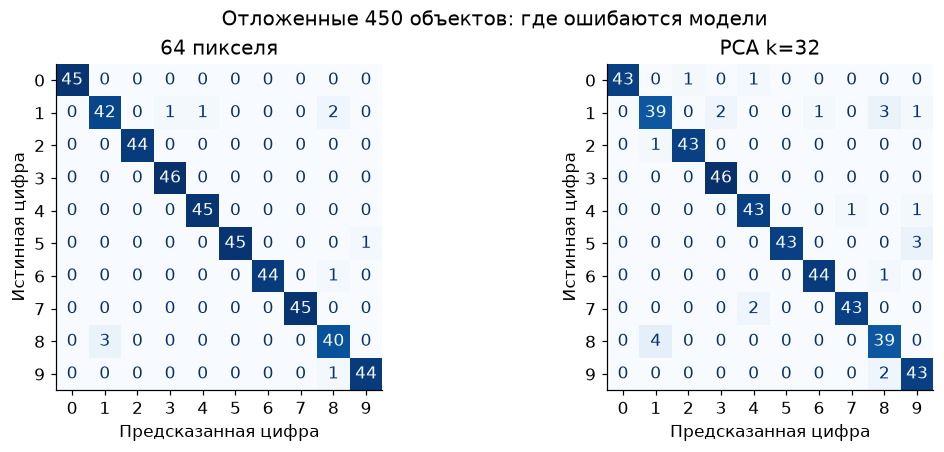

In [8]:
pipelines = {
    "64 пикселя": make_pipeline(StandardScaler(), new_classifier()),
    f"PCA k={selected_rank}": make_pipeline(
        StandardScaler(), PCA(n_components=selected_rank, svd_solver="full"), new_classifier()
    ),
}
final_rows = []
final_predictions = {}
for name, pipeline in pipelines.items():
    tick = perf_counter()
    pipeline.fit(X_train, y_train)
    fit_ms = (perf_counter() - tick) * 1000
    assert pipeline[-1].n_iter_.max() < pipeline[-1].max_iter
    tick = perf_counter()
    pred = pipeline.predict(X_test)
    predict_ms = (perf_counter() - tick) * 1000
    final_predictions[name] = pred
    final_rows.append({"model": name, "features": pipeline[-1].n_features_in_,
                       "test_accuracy": accuracy_score(y_test, pred),
                       "test_macro_f1": f1_score(y_test, pred, average="macro"),
                       "fit_ms": fit_ms, "predict_ms": predict_ms})
final_results = pd.DataFrame(final_rows).set_index("model")
display(final_results.round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, (name, pred) in zip(axes, final_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, colorbar=False,
                                             cmap="Blues", values_format="d")
    ax.set_title(name)
    ax.set_xlabel("Предсказанная цифра")
    ax.set_ylabel("Истинная цифра")
fig.suptitle("Отложенные 450 объектов: где ошибаются модели", fontsize=13)
fig.savefig(OUTPUT_DIR / "04_test_confusion.png", dpi=150)
plt.show()


## Что теперь можно утверждать

- PCA сохранил соответствие «одна строка — один объект» и сократил число признаков.
- Ручная SVD и scikit-learn дали одно подпространство с численной точностью; произвольные знаки осей не меняют результат.
- Сохранённая дисперсия сама по себе не гарантирует сохранение информации о классах: качество классификации показано отдельно.
- Размер таблицы признаков уменьшился, но сам PCA требует хранить среднее, масштаб и матрицу направлений. Полная цепочка может не стать быстрее.

**Попробуйте.** 1) Измените `DEMO_RANK` и сравните изображения. 2) Сравните кривую качества с кривой дисперсии. 3) В отдельном эксперименте замените `StandardScaler()` на `StandardScaler(with_std=False)` во всех цепочках: какие пиксели станут важнее? После просмотра test последующие эксперименты считайте исследовательскими; для новой честной оценки нужен новый отложенный набор.


In [9]:
# Сохраняем воспроизводимые таблицы и краткий отчёт только в OUTPUT_DIR.
rank_results.to_csv(OUTPUT_DIR / "rank_validation.csv")
final_results.to_csv(OUTPUT_DIR / "test_metrics.csv")
compact_table.to_csv(OUTPUT_DIR / "compact_features_train.csv")
pd.DataFrame({"object_id": object_ids, "split": np.where(np.isin(all_idx, train_idx), "train", "test")}).to_csv(
    OUTPUT_DIR / "split_ids.csv", index=False
)
report = {
    "environment": environment, "dataset": "sklearn.load_digits",
    "split_fingerprint": split_fingerprint,
    "n_train": len(train_idx), "n_test": len(test_idx),
    "n_fit": len(fit_idx), "n_validation": len(val_idx),
    "demo_rank": DEMO_RANK, "selected_rank": selected_rank,
    "selection_rule": "max validation accuracy; ties -> smaller rank",
    "manual_svd_projector_error": float(projector_error),
    "test_metrics": final_results.reset_index().to_dict(orient="records"),
    "elapsed_seconds": perf_counter() - started_at,
}
(OUTPUT_DIR / "run_report.json").write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Готово за {report['elapsed_seconds']:.2f} с; результаты: {OUTPUT_DIR.resolve()}")


Готово за 1.71 с; результаты: /Users/alexey/Documents/projects/life/3. Projects/courses/c01_ModAI/02_linalg/notebooks/applications/outputs/d01


## Первичные источники

- [scikit-learn: PCA — центрирование, SVD, компоненты и дисперсия](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).
- [scikit-learn: StandardScaler — статистики только обучающей выборки](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).
- [scikit-learn: load_digits — состав и происхождение набора](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html).
- [scikit-learn: LogisticRegression — модель и параметры](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).

Документация API проверена 7 октября 2026 г.; точные версии текущего запуска напечатаны в начале и сохранены в `run_report.json`.
